In [826]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

In [827]:
ha_df = pd.read_csv('Migrebot_05.09.2026_4efb0a743bd6.csv')

In [828]:
w_df = pd.read_csv('open-meteo-all.csv')

In [829]:
# Русские названия погодных столбцов; колонки дневника уже на русском.
# Дублирующиеся по смыслу исходные поля сохраняют разные названия.
WEATHER_COLUMNS_RU = {
    "time": "Дата погоды",
    "temperature_2m_mean (°C)": "Средняя температура воздуха (°C)",
    "temperature_2m_max (°C)": "Максимальная температура воздуха (°C)",
    "temperature_2m_min (°C)": "Минимальная температура воздуха (°C)",
    "precipitation_sum (mm)": "Сумма осадков (мм)",
    "precipitation_hours (h)": "Продолжительность осадков (ч)",
    "sunshine_duration (s)": "Продолжительность солнечного сияния (с)",
    "wind_gusts_10m_max (km/h)": "Максимальные порывы ветра (км/ч)",
    "relative_humidity_2m_mean (%)": "Средняя относительная влажность (%)",
    "relative_humidity_2m_max (%)": "Максимальная относительная влажность (%)",
    "relative_humidity_2m_min (%)": "Минимальная относительная влажность (%)",
    "pressure_msl_mean (hPa)": "Среднее давление на уровне моря (гПа)",
    "pressure_msl_max (hPa)": "Максимальное давление на уровне моря (гПа)",
    "pressure_msl_min (hPa)": "Минимальное давление на уровне моря (гПа)",
    "cloud_cover_mean (%)": "Средняя облачность (%)",
    "wind_speed_10m_mean (km/h)": "Средняя скорость ветра (км/ч)",
    "vapour_pressure_deficit_max (kPa)": "Максимальный дефицит давления водяного пара (кПа)",
    "cloud_cover_min (%)": "Минимальная облачность (%)",
    "cloud_cover_max (%)": "Максимальная облачность (%)",
    "et0_fao_evapotranspiration_sum (mm)": "Суммарная эталонная эвапотранспирация (мм)",
    "snowfall_water_equivalent_sum (mm)": "Водный эквивалент снегопада (мм)",
    "surface_pressure_mean (hPa)": "Среднее давление у поверхности (гПа)",
    "surface_pressure_max (hPa)": "Максимальное давление у поверхности (гПа)",
    "surface_pressure_min (hPa)": "Минимальное давление у поверхности (гПа)",
    "winddirection_10m_dominant (°)": "Преобладающее направление ветра (°)",
    "wind_direction_10m_dominant (°)": "Преобладающее направление ветра, дубль (°)",
    "wind_speed_10m_max (km/h)": "Максимальная скорость ветра (км/ч)",
    "wind_speed_10m_min (km/h)": "Минимальная скорость ветра (км/ч)",
    "wind_gusts_10m_mean (km/h)": "Средние порывы ветра (км/ч)",
    "wind_gusts_10m_min (km/h)": "Минимальные порывы ветра (км/ч)",
    "weather_code (wmo code)": "Код погоды (ВМО)",
    "shortwave_radiation_sum (MJ/m²)": "Суммарная коротковолновая радиация (МДж/м²)",
    "et0_fao_evapotranspiration (mm)": "Эталонная эвапотранспирация (мм)",
    "sunrise (iso8601)": "Восход солнца",
    "sunset (iso8601)": "Заход солнца",
    "daylight_duration (s)": "Продолжительность светового дня (с)",
    "snowfall_sum (cm)": "Сумма снегопада (см)",
    "rain_sum (mm)": "Сумма дождя (мм)",
    "soil_temperature_7_to_28cm_mean (°C)": "Средняя температура почвы 7–28 см (°C)",
    "soil_moisture_7_to_28cm_mean (m³/m³)": "Средняя влажность почвы 7–28 см (м³/м³)",
    "soil_temperature_28_to_100cm_mean (°C)": "Средняя температура почвы 28–100 см (°C)",
    "soil_moisture_28_to_100cm_mean (m³/m³)": "Средняя влажность почвы 28–100 см (м³/м³)",
    "soil_temperature_0_to_7cm_mean (°C)": "Средняя температура почвы 0–7 см (°C)",
    "soil_moisture_0_to_7cm_mean (m³/m³)": "Средняя влажность почвы 0–7 см (м³/м³)",
    "soil_temperature_0_to_100cm_mean (°C)": "Средняя температура почвы 0–100 см (°C)",
    "soil_moisture_0_to_100cm_mean (m³/m³)": "Средняя влажность почвы 0–100 см (м³/м³)",
    "wet_bulb_temperature_2m_min (°C)": "Минимальная температура влажного термометра (°C)",
    "dew_point_2m_min (°C)": "Минимальная точка росы (°C)",
    "apparent_temperature_min (°C)": "Минимальная ощущаемая температура (°C)",
    "wet_bulb_temperature_2m_max (°C)": "Максимальная температура влажного термометра (°C)",
    "dew_point_2m_max (°C)": "Максимальная точка росы (°C)",
    "apparent_temperature_max (°C)": "Максимальная ощущаемая температура (°C)",
    "wet_bulb_temperature_2m_mean (°C)": "Средняя температура влажного термометра (°C)",
    "dew_point_2m_mean (°C)": "Средняя точка росы (°C)",
    "apparent_temperature_mean (°C)": "Средняя ощущаемая температура (°C)"
}

unknown_columns = set(w_df.columns) - set(WEATHER_COLUMNS_RU) - set(WEATHER_COLUMNS_RU.values())
if unknown_columns:
    raise ValueError(f'Добавьте перевод новых столбцов: {sorted(unknown_columns)}')
w_df = w_df.rename(columns=WEATHER_COLUMNS_RU)
assert w_df.columns.is_unique, 'После переименования появились одинаковые названия'


In [830]:
w_df

,Дата погоды,Средняя температура воздуха (°C),Максимальная температура воздуха (°C),Минимальная температура воздуха (°C),Сумма осадков (мм),Продолжительность осадков (ч),Продолжительность солнечного сияния (с),Максимальные порывы ветра (км/ч),Средняя относительная влажность (%),Максимальная относительная влажность (%),...,Максимальная ощущаемая температура (°C),Код погоды (ВМО),"Преобладающее направление ветра, дубль (°)",Суммарная коротковолновая радиация (МДж/м²),Эталонная эвапотранспирация (мм),Восход солнца,Заход солнца,Продолжительность светового дня (с),Сумма снегопада (см),Сумма дождя (мм)
0,2026-05-03,10.1,12.0,8.8,1.6,14.0,952.24,23.8,96,100,...,11.3,51,344,10.63,1.50,2026-05-03T06:07,2026-05-03T20:13,50710.10,0.0,1.6
1,2026-05-04,11.0,13.5,8.6,5.1,8.0,9484.74,28.1,94,100,...,13.0,63,187,10.63,1.54,2026-05-04T06:06,2026-05-04T20:14,50848.77,0.0,5.1
2,2026-05-05,11.8,14.5,8.8,5.6,13.0,15073.64,25.2,93,100,...,13.8,53,278,11.14,1.62,2026-05-05T06:05,2026-05-05T20:15,50986.51,0.0,5.6
3,2026-05-06,12.4,14.5,10.9,4.0,17.0,20115.02,25.2,92,100,...,13.6,53,259,12.62,1.87,2026-05-06T06:04,2026-05-06T20:16,51123.20,0.0,4.0
4,2026-05-07,12.8,16.6,8.4,0.0,0.0,45407.92,22.3,85,95,...,16.7,3,323,20.37,3.03,2026-05-07T06:02,2026-05-07T20:17,51258.72,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,2026-08-31,22.1,24.8,20.2,15.0,13.0,38920.32,27.7,93,100,...,28.4,63,210,15.62,2.79,2026-08-31T06:38,2026-08-31T19:48,47445.72,0.0,15.0
121,2026-09-01,21.9,24.1,19.8,10.0,19.0,39600.00,25.9,92,98,...,28.2,61,243,15.58,2.80,2026-09-01T06:39,2026-09-01T19:46,47287.24,0.0,10.0
122,2026-09-02,22.1,25.0,18.6,2.6,8.0,43530.60,24.1,90,98,...,28.8,55,250,16.79,3.03,2026-09-02T06:40,2026-09-02T19:45,47127.62,0.0,2.6
123,2026-09-03,22.5,25.5,18.6,0.1,1.0,41040.68,21.6,88,95,...,29.9,51,278,17.08,3.20,2026-09-03T06:41,2026-09-03T19:43,46966.98,0.0,0.1


In [831]:
w_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 55 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Дата погоды                                        125 non-null    str    
 1   Средняя температура воздуха (°C)                   125 non-null    float64
 2   Максимальная температура воздуха (°C)              125 non-null    float64
 3   Минимальная температура воздуха (°C)               125 non-null    float64
 4   Сумма осадков (мм)                                 125 non-null    float64
 5   Продолжительность осадков (ч)                      125 non-null    float64
 6   Продолжительность солнечного сияния (с)            125 non-null    float64
 7   Максимальные порывы ветра (км/ч)                   125 non-null    float64
 8   Средняя относительная влажность (%)                125 non-null    int64  
 9   Максимальная относите

In [832]:
w_df['Дата погоды'] = pd.to_datetime(w_df['Дата погоды'])

In [833]:
w_df['Дата погоды'].describe()

count                    125
mean     2026-07-04 00:00:00
min      2026-05-03 00:00:00
25%      2026-06-03 00:00:00
50%      2026-07-04 00:00:00
75%      2026-08-04 00:00:00
max      2026-09-04 00:00:00
Name: Дата погоды, dtype: object

In [834]:
ha_df = ha_df.loc[:,['Дата', 'Головная боль']]

In [835]:
ha_df['Дата'] = pd.to_datetime(ha_df['Дата'])

In [836]:
ha_df

,Дата,Головная боль
0,2026-09-04,Да
1,2026-09-03,Нет
2,2026-09-01,Нет
3,2026-08-31,Нет
4,2026-08-30,Нет
...,...,...
104,2026-05-07,Да
105,2026-05-06,Да
106,2026-05-05,Нет
107,2026-05-04,Нет


In [837]:
w_df = w_df.merge(ha_df, left_on='Дата погоды', right_on='Дата', how='outer')

In [838]:
w_df['Головная боль'].map(lambda x: 1 if x == 'Да' else 0)

0      1
1      0
2      0
3      1
4      1
      ..
120    0
121    0
122    0
123    0
124    1
Name: Головная боль, Length: 125, dtype: int64

In [839]:
w_df['Боль (0/1)'] = w_df['Головная боль'].map(lambda x: 1 if x == 'Да' else 0)

In [840]:
w_df.head(5)

,Дата погоды,Средняя температура воздуха (°C),Максимальная температура воздуха (°C),Минимальная температура воздуха (°C),Сумма осадков (мм),Продолжительность осадков (ч),Продолжительность солнечного сияния (с),Максимальные порывы ветра (км/ч),Средняя относительная влажность (%),Максимальная относительная влажность (%),...,Суммарная коротковолновая радиация (МДж/м²),Эталонная эвапотранспирация (мм),Восход солнца,Заход солнца,Продолжительность светового дня (с),Сумма снегопада (см),Сумма дождя (мм),Дата,Головная боль,Боль (0/1)
0,2026-05-03,10.1,12.0,8.8,1.6,14.0,952.24,23.8,96,100,...,10.63,1.50,2026-05-03T06:07,2026-05-03T20:13,50710.10,0.0,1.6,2026-05-03,Да,1
1,2026-05-04,11.0,13.5,8.6,5.1,8.0,9484.74,28.1,94,100,...,10.63,1.54,2026-05-04T06:06,2026-05-04T20:14,50848.77,0.0,5.1,2026-05-04,Нет,0
2,2026-05-05,11.8,14.5,8.8,5.6,13.0,15073.64,25.2,93,100,...,11.14,1.62,2026-05-05T06:05,2026-05-05T20:15,50986.51,0.0,5.6,2026-05-05,Нет,0
3,2026-05-06,12.4,14.5,10.9,4.0,17.0,20115.02,25.2,92,100,...,12.62,1.87,2026-05-06T06:04,2026-05-06T20:16,51123.20,0.0,4.0,2026-05-06,Да,1
4,2026-05-07,12.8,16.6,8.4,0.0,0.0,45407.92,22.3,85,95,...,20.37,3.03,2026-05-07T06:02,2026-05-07T20:17,51258.72,0.0,0.0,2026-05-07,Да,1


In [841]:
w_df = w_df.drop(columns=['Дата погоды', 'Восход солнца', 'Заход солнца', 'Дата', 'Головная боль'])

In [ ]:
# Исключаем астрономический признак перед отбором и обучением обеих моделей.
# Дата, восход и заход солнца уже удалены выше.
# Это не устраняет сезонность остальных погодных признаков.
calendar_features = ['Продолжительность светового дня (с)']
removed_calendar_features = [column for column in calendar_features if column in w_df.columns]
w_df = w_df.drop(columns=calendar_features, errors='ignore')
print('Исключены календарные признаки:', removed_calendar_features)


In [842]:
w_df.head()

,Средняя температура воздуха (°C),Максимальная температура воздуха (°C),Минимальная температура воздуха (°C),Сумма осадков (мм),Продолжительность осадков (ч),Продолжительность солнечного сияния (с),Максимальные порывы ветра (км/ч),Средняя относительная влажность (%),Максимальная относительная влажность (%),Минимальная относительная влажность (%),...,Минимальная ощущаемая температура (°C),Максимальная ощущаемая температура (°C),Код погоды (ВМО),"Преобладающее направление ветра, дубль (°)",Суммарная коротковолновая радиация (МДж/м²),Эталонная эвапотранспирация (мм),Продолжительность светового дня (с),Сумма снегопада (см),Сумма дождя (мм),Боль (0/1)
0,10.1,12.0,8.8,1.6,14.0,952.24,23.8,96,100,88,...,7.8,11.3,51,344,10.63,1.50,50710.10,0.0,1.6,1
1,11.0,13.5,8.6,5.1,8.0,9484.74,28.1,94,100,87,...,7.6,13.0,63,187,10.63,1.54,50848.77,0.0,5.1,0
2,11.8,14.5,8.8,5.6,13.0,15073.64,25.2,93,100,84,...,7.8,13.8,53,278,11.14,1.62,50986.51,0.0,5.6,0
3,12.4,14.5,10.9,4.0,17.0,20115.02,25.2,92,100,80,...,10.8,13.6,53,259,12.62,1.87,51123.20,0.0,4.0,1
4,12.8,16.6,8.4,0.0,0.0,45407.92,22.3,85,95,69,...,7.3,16.7,3,323,20.37,3.03,51258.72,0.0,0.0,1


## Анализ и отбор погодных признаков

Отсутствие записи означает отсутствие боли. Исследуем связь с погодой того же дня.

Удаляем постоянные признаки, затем рассматриваем корреляции Пирсона между погодными признаками (без `Боль (0/1)`). Порог `CORR_THRESHOLD = 0.90` применяется к модулю корреляции.

При отборе идём в исходном порядке столбцов CSV: сохраняем признак, только если он не имеет сильной корреляции ни с одним уже сохранённым. Это воспроизводимое правило, а не выбор наиболее связанного с болью признака. Порядок влияет на результат; исключённые признаки и их сохранённые аналоги показаны ниже. Попарный фильтр не устраняет все формы мультиколлинеарности.

Направление ветра перед отбором заменяется косинусом и синусом угла. Север: (1, 0), восток: (0, 1), юг: (−1, 0), запад: (0, −1). Так 359° и 1° оказываются рядом. Компоненты описывают, **откуда** дует ветер; это безразмерное направление, а не скорость движения воздуха. В дереве положительная восточная компонента означает ветер из восточной половины горизонта.

Обе компоненты проходят общий отбор признаков. Логистическая регрессия затем стандартизует их; дерево использует исходный диапазон от −1 до +1. Это по-прежнему преобладающее направление за сутки: смена бриза внутри дня и отсутствие определённого направления при штиле таким кодированием не восстанавливаются.

[Циклическое кодирование в scikit-learn](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html).


In [843]:
CORR_THRESHOLD = 0.99
X_all = w_df.drop(columns=['Боль (0/1)']).copy()

# Направление означает, ОТКУДА дует ветер: 0° — север, 90° — восток.
# Кодируем круг двумя компонентами, не умножая на скорость.
wind_direction_column = 'Преобладающее направление ветра (°)'
wind_direction_duplicate = 'Преобладающее направление ветра, дубль (°)'
wind_degrees = pd.to_numeric(X_all[wind_direction_column], errors='raise')
if not np.isfinite(wind_degrees).all() or not wind_degrees.between(0, 360).all():
    raise ValueError('Направление ветра должно быть конечным числом от 0 до 360 градусов')
if wind_direction_duplicate in X_all:
    duplicate_degrees = pd.to_numeric(X_all[wind_direction_duplicate], errors='raise')
    if not np.allclose(wind_degrees % 360, duplicate_degrees % 360):
        raise ValueError('Два исходных столбца направления ветра расходятся')
wind_radians = np.deg2rad(wind_degrees % 360)
wind_component_columns = [
    'Ветер с севера (+1) / юга (−1)',
    'Ветер с востока (+1) / запада (−1)',
]
X_all = X_all.drop(columns=[wind_direction_column, wind_direction_duplicate], errors='ignore')
X_all[wind_component_columns[0]] = np.cos(wind_radians)
X_all[wind_component_columns[1]] = np.sin(wind_radians)

feature_summary = pd.DataFrame({
    'missing': X_all.isna().sum(),
    'unique': X_all.nunique(),
    'mean': X_all.mean(),
    'std': X_all.std(ddof=0),
})
display(feature_summary)

constant_features = feature_summary.index[feature_summary['unique'] <= 1].tolist()
X_candidates = X_all.drop(columns=constant_features)
print('Постоянные признаки:', constant_features)
if X_candidates.isna().any().any():
    raise ValueError('В погодных признаках есть пропуски: обработайте их перед отбором.')
corr = X_candidates.corr(method='pearson')


,missing,unique,mean,std
Средняя температура воздуха (°C),0,75,20.857600,3.308879
Максимальная температура воздуха (°C),0,67,23.776000,3.229350
Минимальная температура воздуха (°C),0,82,17.768000,4.071002
Сумма осадков (мм),0,74,5.564000,8.254961
Продолжительность осадков (ч),0,25,9.176000,7.280730
Продолжительность солнечного сияния (с),0,117,36643.136400,15281.591369
Максимальные порывы ветра (км/ч),0,52,26.000800,5.971539
Средняя относительная влажность (%),0,25,87.408000,6.026735
Максимальная относительная влажность (%),0,12,97.184000,2.354176
Минимальная относительная влажность (%),0,42,74.400000,10.558030


Постоянные признаки: ['Водный эквивалент снегопада (мм)', 'Сумма снегопада (см)']


,feature_1,feature_2,correlation
3,Сумма осадков (мм),Сумма дождя (мм),1.000000
12,Суммарная эталонная эвапотранспирация (мм),Эталонная эвапотранспирация (мм),1.000000
5,Максимальное давление на уровне моря (гПа),Максимальное давление у поверхности (гПа),1.000000
6,Минимальное давление на уровне моря (гПа),Минимальное давление у поверхности (гПа),1.000000
4,Среднее давление на уровне моря (гПа),Среднее давление у поверхности (гПа),0.999963
7,Средняя температура почвы 28–100 см (°C),Средняя температура почвы 0–100 см (°C),0.996211
1,Средняя температура воздуха (°C),Средняя ощущаемая температура (°C),0.995435
2,Минимальная температура воздуха (°C),Минимальная ощущаемая температура (°C),0.994752
11,Средняя температура влажного термометра (°C),Средняя точка росы (°C),0.993650
10,Максимальная температура влажного термометра (°C),Максимальная точка росы (°C),0.992114


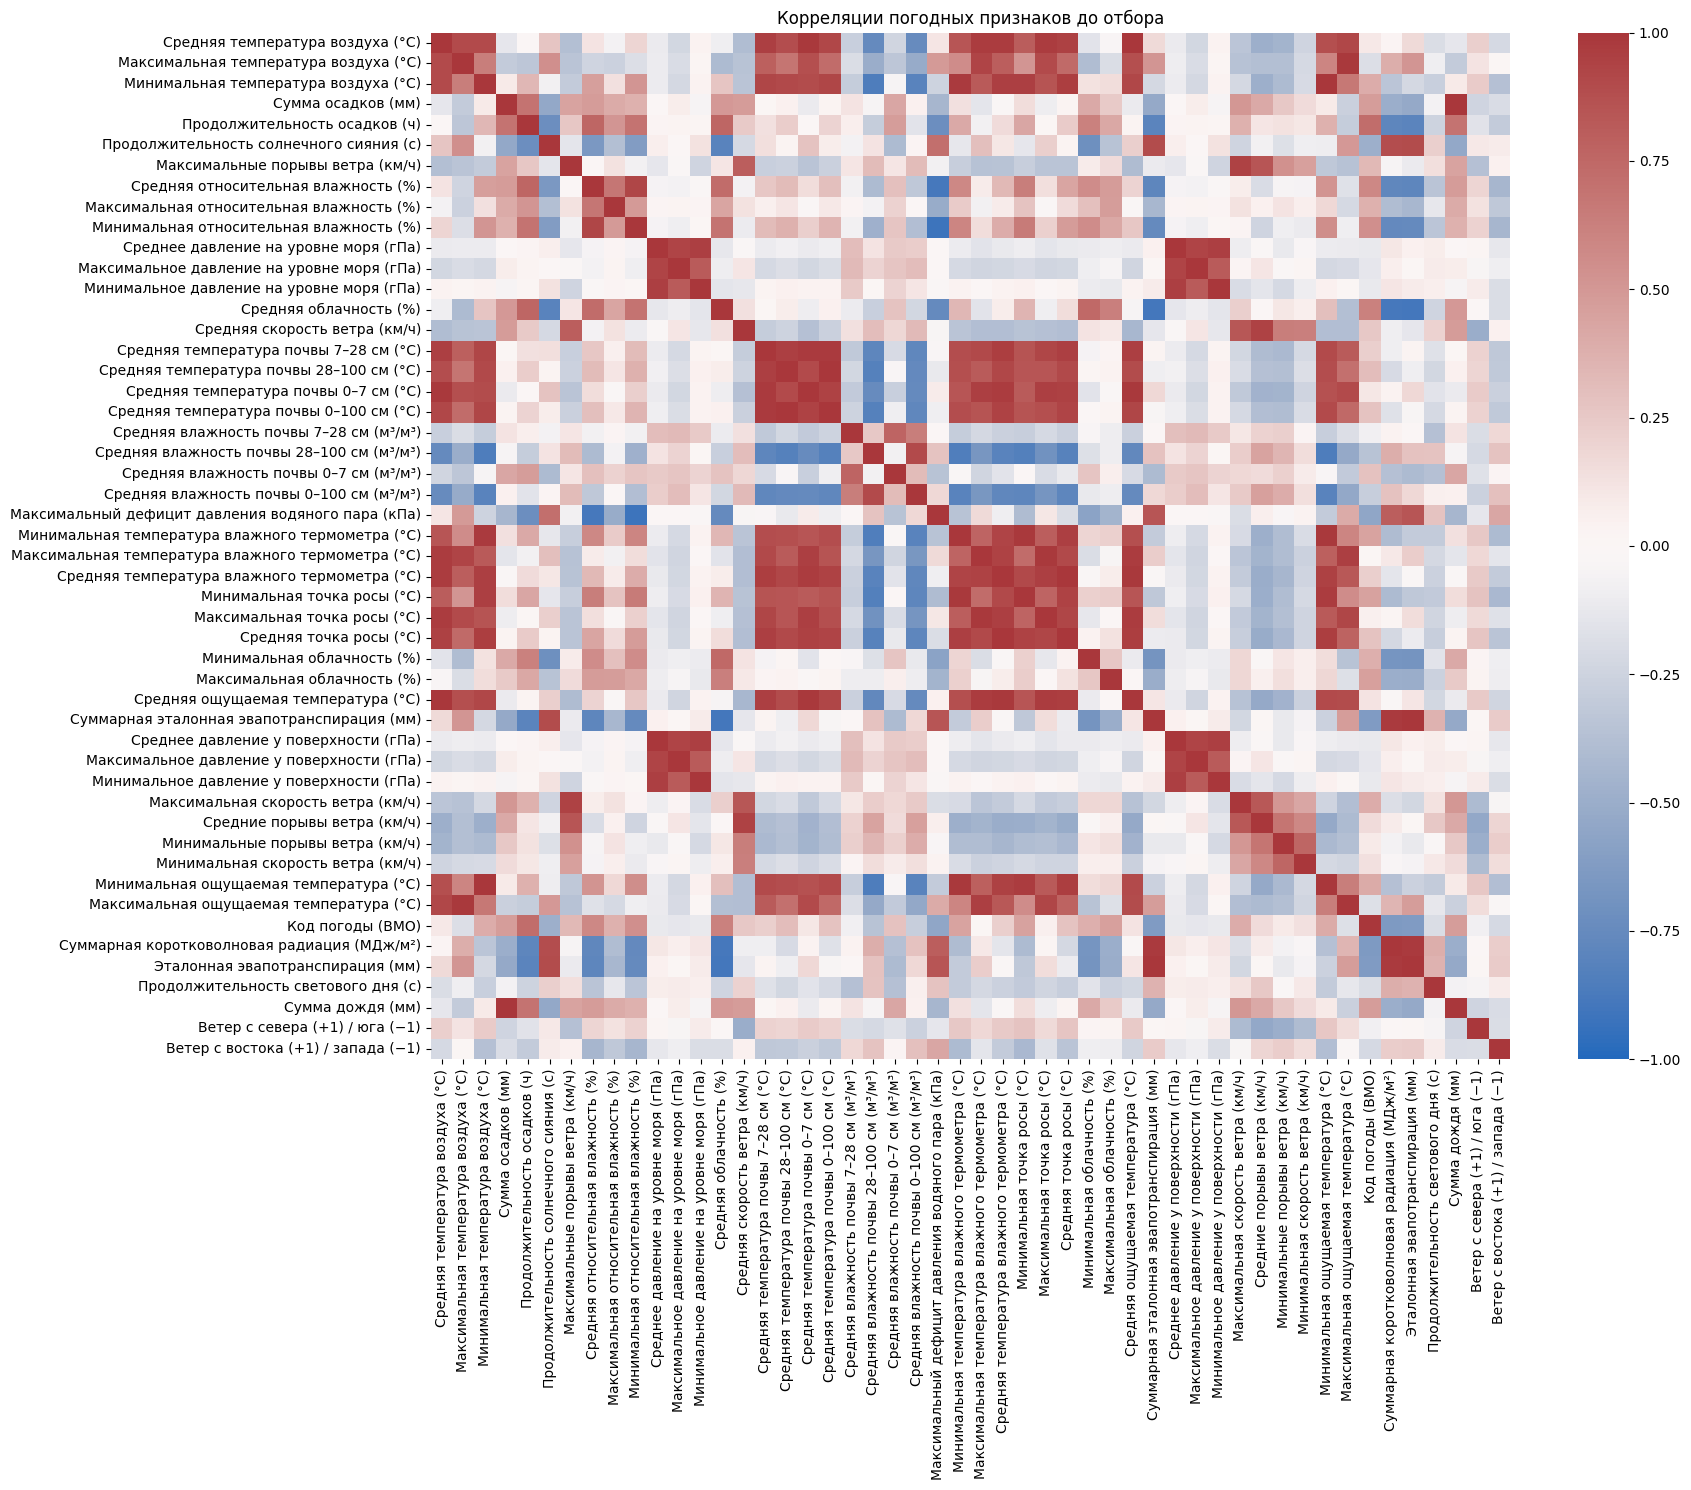

In [844]:
high_corr_pairs = pd.DataFrame([
    {'feature_1': left, 'feature_2': right, 'correlation': corr.loc[left, right]}
    for i, left in enumerate(corr.columns)
    for right in corr.columns[i + 1:]
    if abs(corr.loc[left, right]) >= CORR_THRESHOLD
], columns=['feature_1', 'feature_2', 'correlation'])
high_corr_pairs = high_corr_pairs.sort_values(
    'correlation', key=lambda values: values.abs(), ascending=False
)
display(high_corr_pairs)

plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.title('Корреляции погодных признаков до отбора')
plt.tight_layout()
plt.show()


,excluded_feature,retained_feature,correlation
0,Средняя температура почвы 0–7 см (°C),Средняя температура воздуха (°C),0.990482
1,Средняя температура почвы 0–100 см (°C),Средняя температура почвы 28–100 см (°C),0.996211
2,Минимальная точка росы (°C),Минимальная температура влажного термометра (°C),0.991733
3,Максимальная точка росы (°C),Максимальная температура влажного термометра (°C),0.992114
4,Средняя точка росы (°C),Средняя температура влажного термометра (°C),0.993650
5,Средняя ощущаемая температура (°C),Средняя температура воздуха (°C),0.995435
6,Среднее давление у поверхности (гПа),Среднее давление на уровне моря (гПа),0.999963
7,Максимальное давление у поверхности (гПа),Максимальное давление на уровне моря (гПа),1.000000
8,Минимальное давление у поверхности (гПа),Минимальное давление на уровне моря (гПа),1.000000
9,Минимальная ощущаемая температура (°C),Минимальная температура воздуха (°C),0.994752


Было: 52; постоянных: 2; исключено по корреляции: 12; осталось: 38


0                      Средняя температура воздуха (°C)
1                 Максимальная температура воздуха (°C)
2                  Минимальная температура воздуха (°C)
3                                    Сумма осадков (мм)
4                         Продолжительность осадков (ч)
5               Продолжительность солнечного сияния (с)
6                      Максимальные порывы ветра (км/ч)
7                   Средняя относительная влажность (%)
8              Максимальная относительная влажность (%)
9               Минимальная относительная влажность (%)
10                Среднее давление на уровне моря (гПа)
11           Максимальное давление на уровне моря (гПа)
12            Минимальное давление на уровне моря (гПа)
13                               Средняя облачность (%)
14                        Средняя скорость ветра (км/ч)
15               Средняя температура почвы 7–28 см (°C)
16             Средняя температура почвы 28–100 см (°C)
17              Средняя влажность почвы 7–28 см 

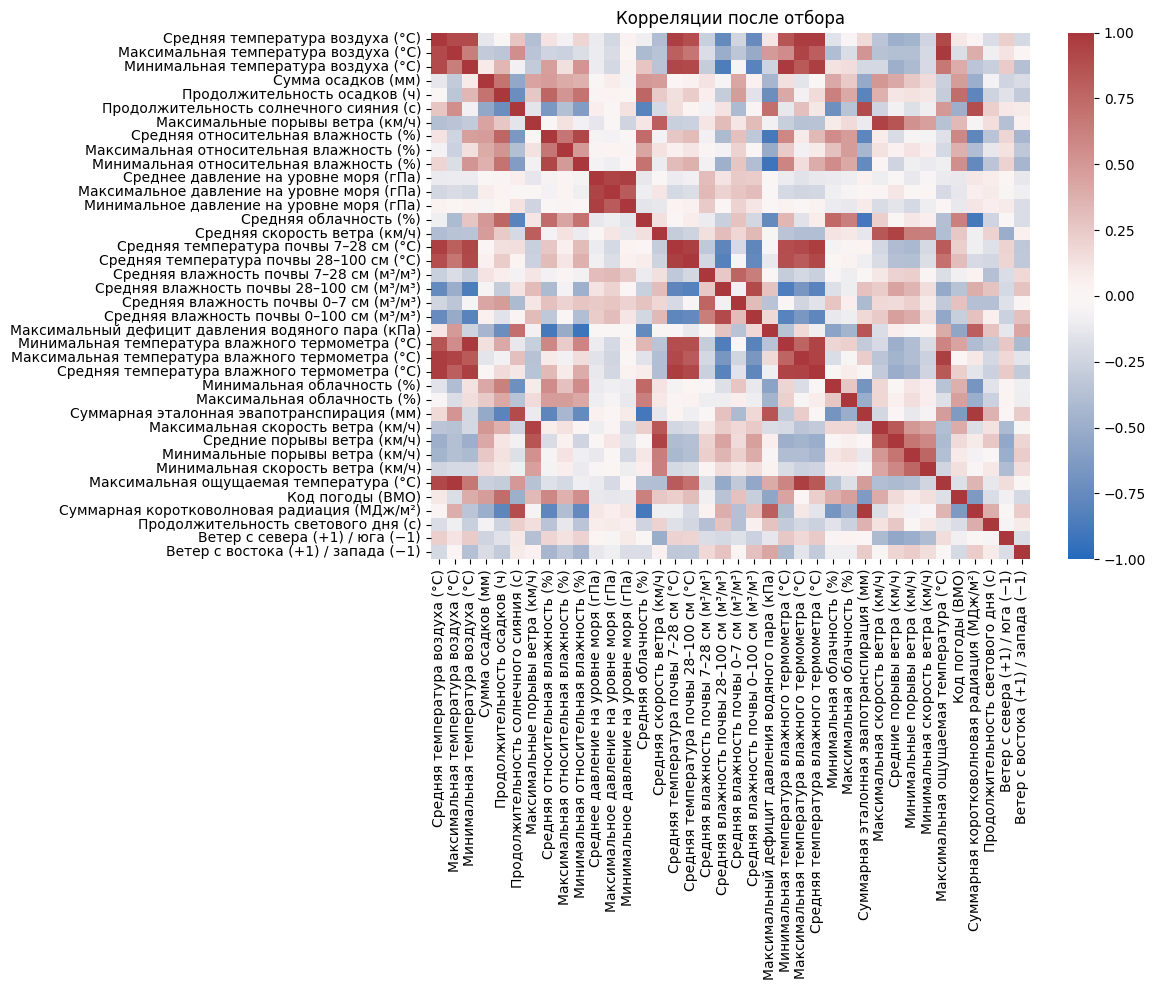

In [845]:
selected_features = []
excluded = []
for feature in X_candidates.columns:
    correlated_with = [
        kept for kept in selected_features
        if abs(corr.loc[feature, kept]) >= CORR_THRESHOLD
    ]
    if correlated_with:
        representative = max(correlated_with, key=lambda kept: abs(corr.loc[feature, kept]))
        excluded.append({
            'excluded_feature': feature,
            'retained_feature': representative,
            'correlation': corr.loc[feature, representative],
        })
    else:
        selected_features.append(feature)

excluded_features = pd.DataFrame(
    excluded, columns=['excluded_feature', 'retained_feature', 'correlation']
)
display(excluded_features)
X_selected = X_all.loc[:, selected_features].copy()
print(f'Было: {X_all.shape[1]}; постоянных: {len(constant_features)}; '
      f'исключено по корреляции: {len(excluded)}; осталось: {X_selected.shape[1]}')
display(pd.Series(selected_features, name='retained_feature'))

corr_selected = X_selected.corr()
assert all(
    abs(corr_selected.loc[left, right]) < CORR_THRESHOLD
    for i, left in enumerate(selected_features)
    for right in selected_features[i + 1:]
)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_selected, cmap='vlag', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.title('Корреляции после отбора')
plt.tight_layout()
plt.show()


## Обучение и коэффициенты

Модель обучается на отобранных и стандартизованных признаках. Коэффициент описывает изменение логарифма шансов боли при увеличении признака на одно стандартное отклонение при фиксированных остальных признаках. `odds_ratio_per_sd` — множитель шансов, не вероятности. Это ассоциации в текущей выборке; устойчивость коэффициентов здесь не проверяется. AUC ниже рассчитан на обучающей выборке.


In [846]:
SC = StandardScaler()

In [847]:
X = X_selected.copy()

In [848]:
X

,Средняя температура воздуха (°C),Максимальная температура воздуха (°C),Минимальная температура воздуха (°C),Сумма осадков (мм),Продолжительность осадков (ч),Продолжительность солнечного сияния (с),Максимальные порывы ветра (км/ч),Средняя относительная влажность (%),Максимальная относительная влажность (%),Минимальная относительная влажность (%),...,Максимальная скорость ветра (км/ч),Средние порывы ветра (км/ч),Минимальные порывы ветра (км/ч),Минимальная скорость ветра (км/ч),Максимальная ощущаемая температура (°C),Код погоды (ВМО),Суммарная коротковолновая радиация (МДж/м²),Продолжительность светового дня (с),Ветер с севера (+1) / юга (−1),Ветер с востока (+1) / запада (−1)
0,10.1,12.0,8.8,1.6,14.0,952.24,23.8,96,100,88,...,6.6,13.1,8.3,1.8,11.3,51,10.63,50710.10,0.961262,-0.275637
1,11.0,13.5,8.6,5.1,8.0,9484.74,28.1,94,100,87,...,10.5,19.3,8.6,0.4,13.0,63,10.63,50848.77,-0.992546,-0.121869
2,11.8,14.5,8.8,5.6,13.0,15073.64,25.2,93,100,84,...,10.2,16.0,7.9,1.7,13.8,53,11.14,50986.51,0.139173,-0.990268
3,12.4,14.5,10.9,4.0,17.0,20115.02,25.2,92,100,80,...,9.5,15.2,6.5,0.4,13.6,53,12.62,51123.20,-0.190809,-0.981627
4,12.8,16.6,8.4,0.0,0.0,45407.92,22.3,85,95,69,...,7.8,13.4,4.3,0.9,16.7,3,20.37,51258.72,0.798636,-0.601815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,22.1,24.8,20.2,15.0,13.0,38920.32,27.7,93,100,79,...,10.2,15.4,8.6,1.5,28.4,63,15.62,47445.72,-0.866025,-0.500000
121,21.9,24.1,19.8,10.0,19.0,39600.00,25.9,92,98,82,...,7.7,13.0,6.5,0.6,28.2,61,15.58,47287.24,-0.453990,-0.891007
122,22.1,25.0,18.6,2.6,8.0,43530.60,24.1,90,98,79,...,9.1,13.8,5.0,0.6,28.8,55,16.79,47127.62,-0.342020,-0.939693
123,22.5,25.5,18.6,0.1,1.0,41040.68,21.6,88,95,79,...,7.6,14.2,3.6,0.2,29.9,51,17.08,46966.98,0.139173,-0.990268


In [849]:
y = w_df['Боль (0/1)']

In [850]:
y

0      1
1      0
2      0
3      1
4      1
      ..
120    0
121    0
122    0
123    0
124    1
Name: Боль (0/1), Length: 125, dtype: int64

In [851]:
X = SC.fit_transform(X)

In [852]:
model = LogisticRegression(verbose=1)

In [853]:
model.fit(X, y)

,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem

In [854]:
model.coef_

array([[ 4.30967713e-02,  1.39353269e-01,  5.62690124e-01,
        -4.70038738e-01, -5.91226460e-03, -7.02682095e-01,
         2.66349860e-01, -1.42352436e+00,  3.88267612e-02,
        -1.19939944e-02,  3.28250151e-01,  4.87345257e-01,
        -4.13780031e-01,  6.58211195e-01,  7.04105204e-05,
         8.23231879e-02,  2.83027026e-01,  1.78356737e-02,
         4.08678241e-01, -2.23603003e-01,  3.10293747e-01,
        -5.95180019e-01, -4.85230535e-01,  4.80347772e-02,
        -2.35241291e-01,  5.43897223e-01, -4.10066828e-01,
         1.97543153e-01,  3.80347000e-01, -8.17390739e-01,
         5.44538186e-01,  5.79471350e-02,  1.05226195e-01,
         1.78181337e-01,  3.44858686e-01, -2.73296852e-02,
         8.95589108e-02, -2.59100516e-01]])

In [855]:
model.coef_[0].shape

(38,)

In [856]:
X_selected.columns.shape

(38,)

In [857]:
model.predict_proba(X)[:,1]

array([0.72358232, 0.04124589, 0.23011025, 0.42959943, 0.16042423,
       0.13116067, 0.5961057 , 0.2187178 , 0.49368266, 0.4470695 ,
       0.37420865, 0.11982393, 0.35357728, 0.1876179 , 0.06878156,
       0.79955801, 0.50785838, 0.07055326, 0.28726961, 0.25363886,
       0.16377639, 0.29283569, 0.19361731, 0.18000076, 0.51592859,
       0.20098309, 0.13756608, 0.20099054, 0.52383841, 0.88978195,
       0.23599246, 0.31075349, 0.02078981, 0.22911302, 0.69232278,
       0.20905147, 0.12504116, 0.2618707 , 0.27167142, 0.29555612,
       0.03982455, 0.29927074, 0.10758295, 0.01050162, 0.14478385,
       0.30603892, 0.19429213, 0.11742369, 0.24864143, 0.47989113,
       0.0281741 , 0.19326653, 0.09016399, 0.26057721, 0.4921259 ,
       0.06220194, 0.31005316, 0.57071245, 0.31368386, 0.30904414,
       0.05070516, 0.06158689, 0.0283806 , 0.02694215, 0.23176345,
       0.06755695, 0.12609806, 0.04997046, 0.04356564, 0.05728119,
       0.04196479, 0.14713602, 0.09542921, 0.25116483, 0.33050

In [858]:
model.classes_

array([0, 1])

In [859]:
roc_auc_score(y, model.predict_proba(X)[:,1])

0.870049504950495

In [860]:
col_importance = pd.DataFrame({
    'feature': selected_features,
    'coefficient': model.coef_[0],
    'abs_coefficient': np.abs(model.coef_[0]),
    'odds_ratio_per_sd': np.exp(model.coef_[0]),
}).sort_values('abs_coefficient', ascending=False)

In [861]:
col_importance

,feature,coefficient,abs_coefficient,odds_ratio_per_sd
7,Средняя относительная влажность (%),-1.423524,1.423524,0.240864
29,Средние порывы ветра (км/ч),-0.817391,0.817391,0.441582
5,Продолжительность солнечного сияния (с),-0.702682,0.702682,0.495255
13,Средняя облачность (%),0.658211,0.658211,1.931334
21,Максимальный дефицит давления водяного пара (кПа),-0.595180,0.595180,0.551463
2,Минимальная температура воздуха (°C),0.562690,0.562690,1.755388
30,Минимальные порывы ветра (км/ч),0.544538,0.544538,1.723812
25,Минимальная облачность (%),0.543897,0.543897,1.722708
11,Максимальное давление на уровне моря (гПа),0.487345,0.487345,1.627989
22,Минимальная температура влажного термометра (°C),-0.485231,0.485231,0.615555


## Простое дерево решений

Используем отобранные признаки без стандартизации, с порогами в исходных единицах. Солнечное сияние и длину дня переводим в часы. Направление ветра представлено двумя циклическими компонентами от −1 до +1. Код погоды исключён.

Параметры обучения находятся в `TREE_PARAMS`, оформление — в `TREE_STYLE`. Текущие ограничения: глубина до 10, минимум 5 дней в листе. Для более компактных правил можно попробовать глубину 3 и минимум 10–15 дней в листе. Увеличение `ccp_alpha` обрезает дерево; `max_leaf_nodes` ограничивает число листьев.

После изменения обучения выполните ячейку обучения и следующие ячейки. После изменения только дизайна достаточно выполнить ячейку визуализации. `display_max_depth` скрывает нижние уровни только на рисунке, не меняя модель и таблицу правил.

При `class_weight=None` распределение классов в узлах соответствует наблюдениям. При `'balanced'` или словаре весов распределение и цвет отражают взвешенные классы; таблица листьев по-прежнему показывает фактические частоты. Метрики рассчитаны на обучающей выборке, устойчивость правил не проверяется.

Справка: [параметры модели](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html), [визуализация](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html).


In [862]:
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Настройки обучения (не зависят от дизайна картинки).
TREE_PARAMS = {
    'max_depth': 10,              # Максимальная глубина; None — без ограничения.
    'min_samples_leaf': 3,        # Минимум дней в листе; float — доля выборки.
    'min_samples_split': 2,       # Минимум дней в узле для попытки разделения.
    'max_leaf_nodes': None,       # Максимум листьев, например 8; None — без ограничения.
    'criterion': 'gini',          # 'gini', 'entropy' или 'log_loss'.
    'splitter': 'best',           # 'best' или 'random'.
    'max_features': None,         # None — все; также 'sqrt', 'log2', число или доля.
    'min_impurity_decrease': 0.01, # Минимальное улучшение для разделения.
    'ccp_alpha': 0.0,             # Сила обрезки дерева; например 0.005 или 0.01.
    'class_weight': None,        # None, 'balanced' или {0: 1, 1: 2}.
    'random_state': 42,          # Для воспроизводимости.
}
X_tree = X_selected.drop(columns=[
    'Код погоды (ВМО)',
], errors='ignore').copy()
for feature in ['Продолжительность солнечного сияния (с)', 'Продолжительность светового дня (с)']:
    if feature in X_tree.columns:
        X_tree[feature.replace('(с)', '(ч)')] = X_tree.pop(feature) / 3600

tree_model = DecisionTreeClassifier(**TREE_PARAMS)
tree_model.fit(X_tree, y)
pain_class_index = list(tree_model.classes_).index(1)
tree_probabilities = tree_model.predict_proba(X_tree)[:, pain_class_index]
print(f'Дней: {len(y)}; дней с болью: {int(y.sum())}; доля боли: {y.mean():.1%}')
print(f'Глубина: {tree_model.get_depth()}; листьев: {tree_model.get_n_leaves()}')
print(f'ROC-AUC на обучающей выборке: {roc_auc_score(y, tree_probabilities):.3f}')


Дней: 125; дней с болью: 24; доля боли: 19.2%
Глубина: 5; листьев: 9
ROC-AUC на обучающей выборке: 0.939


Визуализация сохранена: C:\Users\swald\Desktop\Git\Case_3_headache\decision_tree.png
Визуализация сохранена: C:\Users\swald\Desktop\Git\Case_3_headache\decision_tree.svg


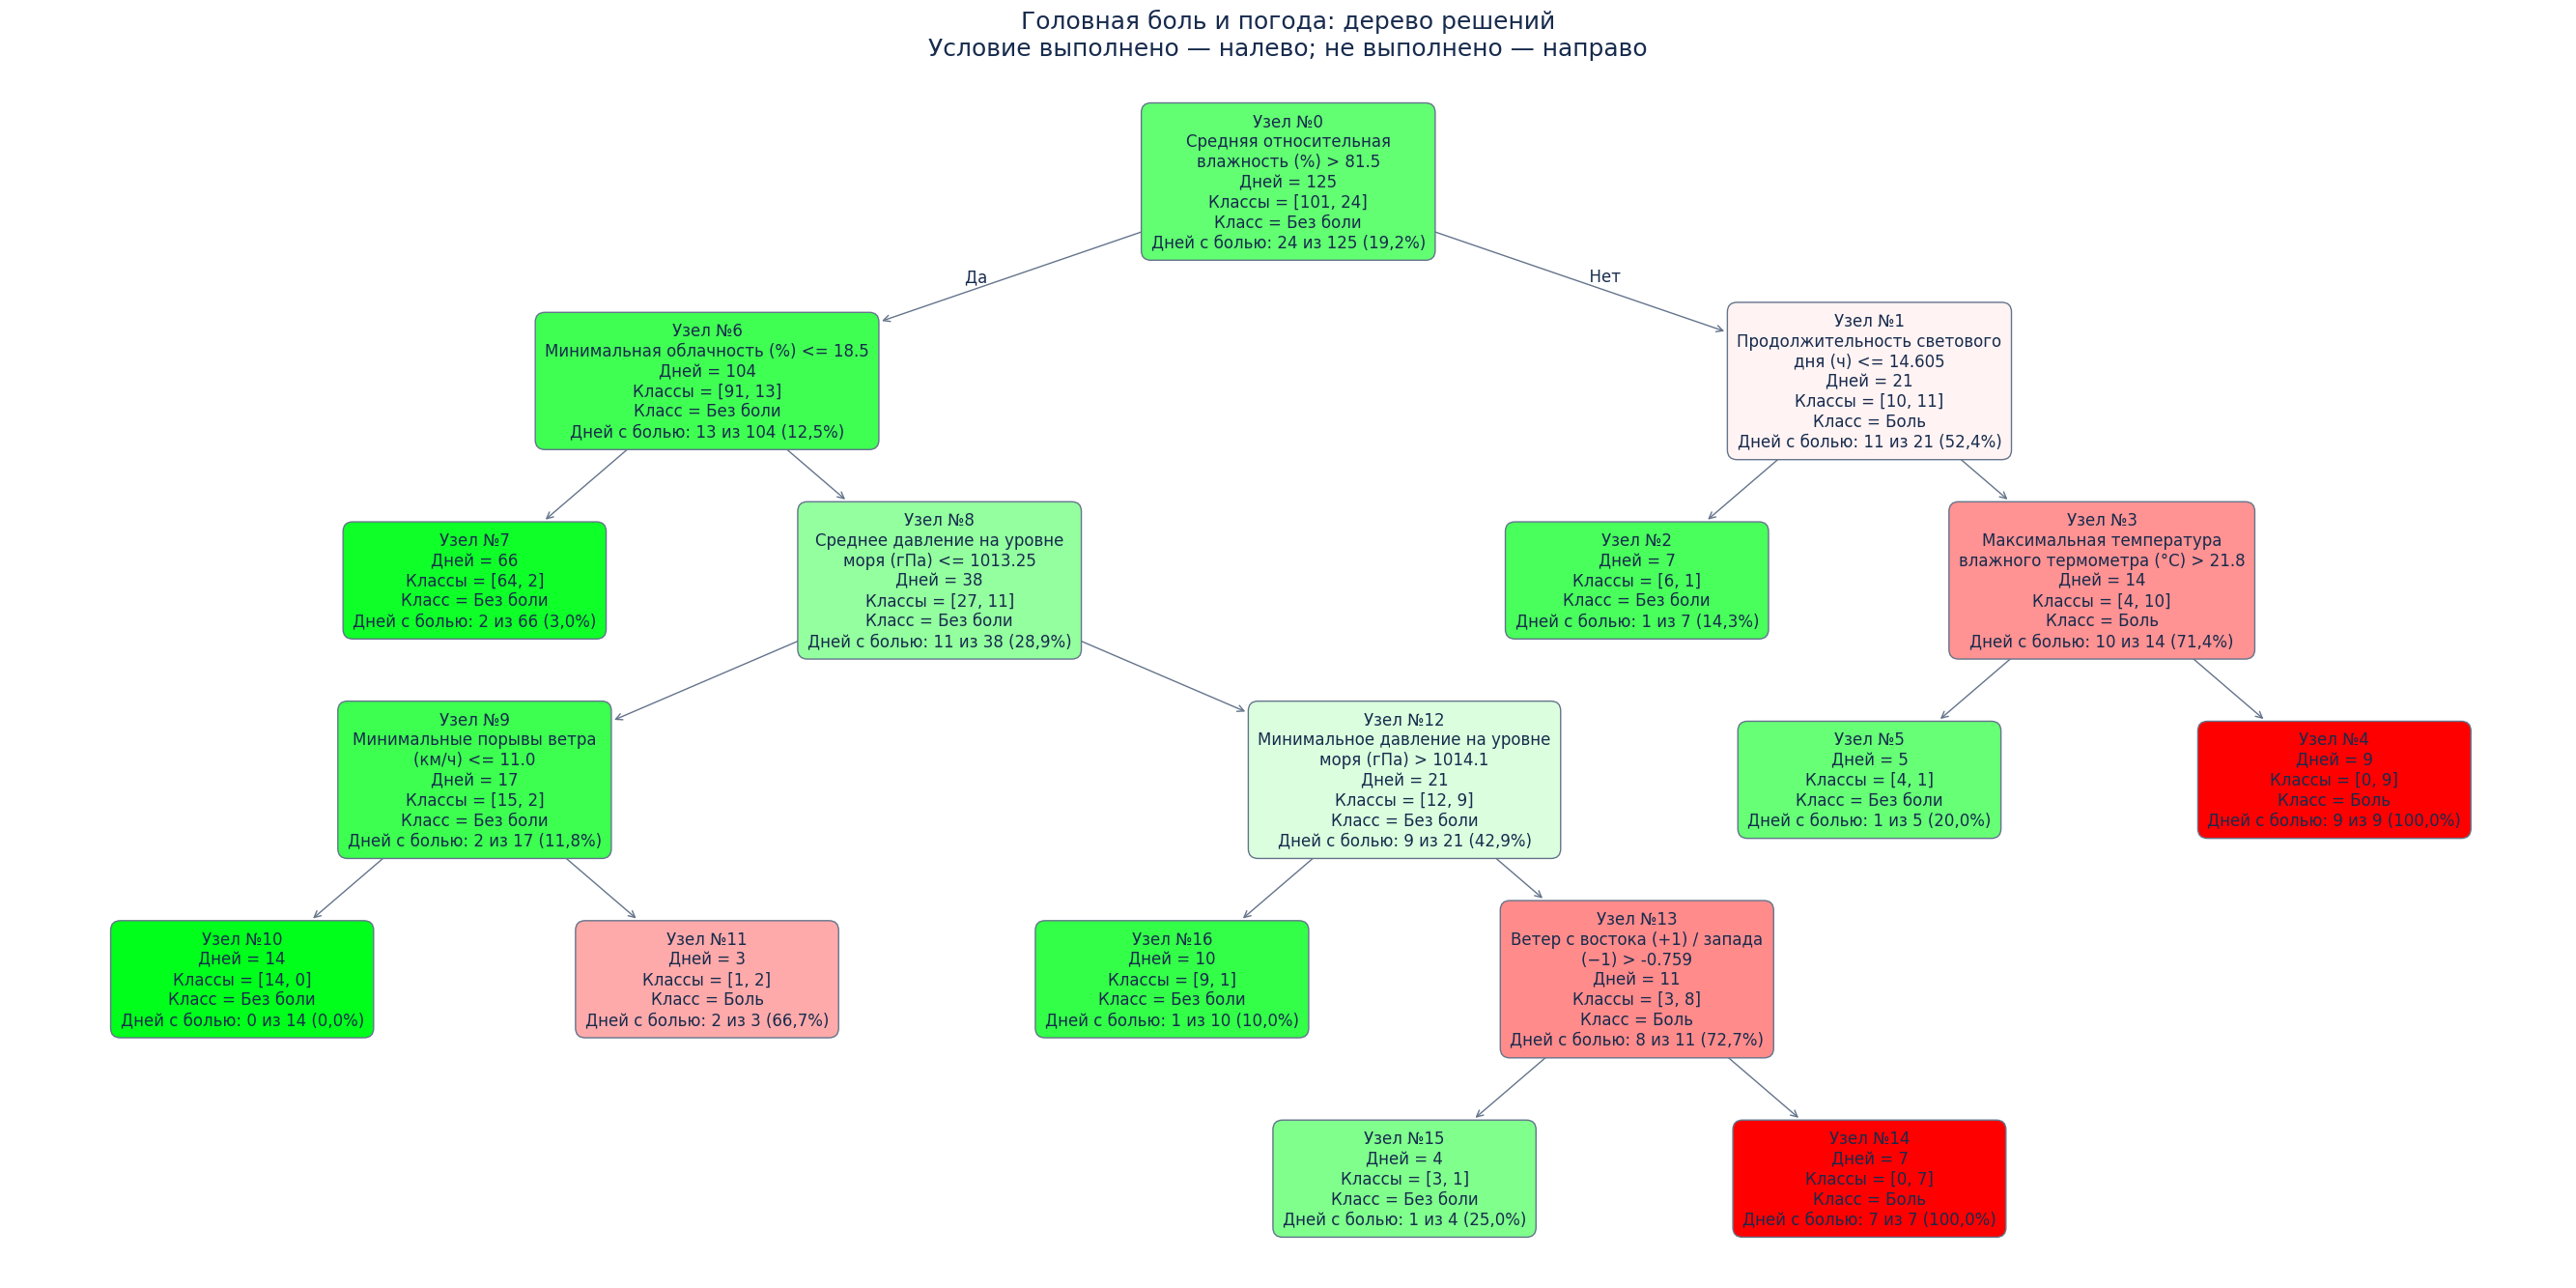

In [863]:
import re
import textwrap
from copy import deepcopy
from matplotlib.colors import to_rgb

# Настройки оформления: меняйте их и запускайте только эту ячейку.
TREE_STYLE = {
    'figsize': None,                 # None — автоматически; либо (32, 18) в дюймах.
    'width_per_leaf': 3.5,           # Ширина при автоматическом размере.
    'height_per_level': 2.8,
    # Новые настройки размеров; прежние настройки ниже сохранены.
    'layout_width_scale': 0.85,     # < 1 — меньше горизонтальные расстояния (1 — прежние).
    'layout_height_scale': 0.80,    # < 1 — меньше расстояния между уровнями (1 — прежние).
    'node_scale': 1.20,             # Масштаб текста и узлов (1 — прежний размер).
    'node_padding': 0.60,           # Внутренние поля узла в долях размера шрифта; None — прежние.
    'font_size': 10,                 # None — автоматический подбор plot_tree.
    'font_family': 'DejaVu Sans',    # Шрифт с поддержкой кириллицы.
    'wrap_width': 30,                # Перенос названий; None — без переноса.
    'precision': 3,                  # Знаки после запятой в порогах.
    'display_max_depth': None,       # Только глубина рисунка, например 3.
    'filled': True,
    'rounded': True,
    'show_impurity': False,
    'show_node_ids': True,
    'show_pain_rate': True,          # Число и процент дней с болью в каждом узле.
    'pain_rate_precision': 1,        # Знаки после запятой в проценте боли.
    'sort_branches_by_pain_rate': True, # В каждом сплите меньшая доля боли слева.
    'proportion': False,             # True — доли классов и проценты выборки.
    'class_names': ['Без боли', 'Боль'], # В порядке классов 0, 1.
    'class_colors': ["#00FF1A", "#FF0000"], # Без боли / боль; None — цвета sklearn.
    'text_color': '#172B4D',
    'edge_color': '#64748B',
    'line_width': 1.0,
    'background': '#FFFFFF',
    'title': 'Головная боль и погода: дерево решений',
    'title_size': 18,
    'dpi': 200,
    'output_stem': 'decision_tree',  # Имя файла без расширения, можно указать папку.
    'formats': ['png', 'svg'],       # PNG для просмотра; SVG масштабируется без потерь.
}

style = TREE_STYLE
# Фактические дни, проходящие через каждый узел, включая внутренние сплиты.
# Не используем tree_.value: при class_weight оно содержит взвешенные значения.
node_paths = tree_model.decision_path(X_tree)
node_days = np.asarray(node_paths.sum(axis=0)).ravel().astype(int)
node_pain_days = np.asarray(node_paths.T @ (y.to_numpy() == 1).astype(int)).ravel().astype(int)

def orient_tree_for_display(model, days, pain_days, sort_branches=True):
    # Эта копия предназначена только для plot_tree, не для predict/apply/export_text.
    # После перестановки детей знак условия на рисунке меняем с <= на >.
    display_model = deepcopy(model)
    reversed_nodes = set()
    if sort_branches:
        structure = display_model.tree_
        for node_id in range(structure.node_count):
            left = int(structure.children_left[node_id])
            right = int(structure.children_right[node_id])
            if left == right or days[left] == 0 or days[right] == 0:
                continue
            if pain_days[left] / days[left] > pain_days[right] / days[right]:
                structure.children_left[node_id] = right
                structure.children_right[node_id] = left
                reversed_nodes.add(node_id)
    return display_model, reversed_nodes

display_tree_model, reversed_nodes = orient_tree_for_display(
    tree_model, node_days, node_pain_days, style['sort_branches_by_pain_rate']
)
visible_depth = tree_model.get_depth()
if style['display_max_depth'] is not None:
    visible_depth = min(visible_depth, style['display_max_depth'])
figsize = style['figsize'] or (
    max(24, min(tree_model.get_n_leaves(), 2 ** visible_depth) * style['width_per_leaf']),
    max(10, (visible_depth + 1) * style['height_per_level']),
)
feature_labels = [
    textwrap.fill(name, width=style['wrap_width'], break_long_words=False,
                  break_on_hyphens=False) if style['wrap_width'] else name
    for name in X_tree.columns
]
with plt.rc_context({'font.family': style['font_family']}):
    # Масштабируем полотно отдельно от шрифта: узлы становятся ближе друг к другу.
    # Слишком маленькое полотно или слишком большие узлы могут давать наложения.
    if min(style['layout_width_scale'], style['layout_height_scale'], style['node_scale']) <= 0:
        raise ValueError('Масштабы полотна и узлов должны быть положительными')
    if style['node_padding'] is not None and style['node_padding'] < 0:
        raise ValueError('Внутренние поля узла не могут быть отрицательными')
    scaled_figsize = (
        figsize[0] * style['layout_width_scale'],
        figsize[1] * style['layout_height_scale'],
    )
    fig, ax = plt.subplots(figsize=scaled_figsize, facecolor=style['background'])
    ax.set_facecolor(style['background'])
    annotations = plot_tree(
        display_tree_model,
        feature_names=feature_labels,
        class_names=style['class_names'],
        max_depth=style['display_max_depth'],
        filled=style['filled'],
        rounded=style['rounded'],
        impurity=style['show_impurity'],
        proportion=style['proportion'],
        node_ids=True,  # Нужны для настройки цветов; скрываются ниже при необходимости.
        precision=style['precision'],
        fontsize=style['font_size'],
        ax=ax,
    )
    for annotation in annotations:
        label = annotation.get_text()
        match = re.search(r'node #(\d+)', label)
        if match and int(match.group(1)) in reversed_nodes:
            # Строгое > сохраняет исходное распределение при равенстве порогу.
            label = label.replace(' <= ', ' > ', 1).replace(' ≤ ', ' > ', 1)
        box = annotation.get_bbox_patch()
        if match and style['show_pain_rate']:
            node_id = int(match.group(1))
            days = node_days[node_id]
            pain_days = node_pain_days[node_id]
            percentage = (
                format(100 * pain_days / days, f".{style['pain_rate_precision']}f").replace('.', ',')
                if days else '—'
            )
            label += f'\nДней с болью: {pain_days} из {days} ({percentage}%)'
        if match and box is not None and style['filled'] and style['class_colors']:
            node_id = int(match.group(1))
            counts = tree_model.tree_.value[node_id].ravel()
            shares = counts / counts.sum()
            dominant = int(np.argmax(shares))
            strength = float(abs(shares[1] - shares[0]))
            base = np.array(to_rgb(style['class_colors'][dominant]))
            box.set_facecolor((1 - strength) * np.ones(3) + strength * base)
        if not style['show_node_ids']:
            label = re.sub(r'node #\d+\n?', '', label)
        label = label.replace('node #', 'Узел №')
        label = label.replace('samples =', 'Дней =')
        label = label.replace('value =', 'Классы =')
        label = label.replace('class =', 'Класс =')
        label = label.replace('True', 'Да').replace('False', 'Нет')
        annotation.set_text(label)
        annotation.set_color(style['text_color'])
        annotation.set_fontsize(annotation.get_fontsize() * style['node_scale'])
        if box is not None:
            if style['node_padding'] is not None:
                box_style = 'round' if style['rounded'] else 'square'
                box.set_boxstyle(box_style, pad=style['node_padding'])
            box.set_edgecolor(style['edge_color'])
            box.set_linewidth(style['line_width'])
        if annotation.arrow_patch is not None:
            annotation.arrow_patch.set_color(style['edge_color'])
            annotation.arrow_patch.set_linewidth(style['line_width'])
    ax.set_title(
        style['title'] + '\nУсловие выполнено — налево; не выполнено — направо',
        fontsize=style['title_size'], color=style['text_color'], pad=20,
    )
    fig.tight_layout()
    output_stem = Path(style['output_stem']).expanduser()
    output_stem.parent.mkdir(parents=True, exist_ok=True)
    for image_format in style['formats']:
        image_path = output_stem.parent / (output_stem.name + '.' + image_format)
        fig.savefig(image_path, format=image_format, dpi=style['dpi'],
                    bbox_inches='tight', facecolor=style['background'])
        print(f'Визуализация сохранена: {image_path.resolve()}')
    plt.show()


### Как читать дерево

Начните сверху: если показанное условие (`<=` или `>`) выполнено, переходите налево; иначе — направо. Цепочка условий до листа описывает группу дней.

При `sort_branches_by_pain_rate=True` в каждом сплите слева расположена дочерняя ветвь с меньшей фактической долей дней с болью, справа — с большей (при равенстве порядок сохраняется). Это локальное упорядочивание: все листья не обязательно идут строго по возрастанию. При развороте условие меняется с `<=` на строгое `>`, чтобы сохранить принадлежность дней, равных порогу. Модель, номера узлов, предсказания и текстовые правила ниже остаются исходными; меняется только рисунок.

`Дней` — число дней в узле; `Классы = [без боли, с болью]` — распределение. Например, `[12, 8]` означает 8 дней боли из 20, то есть 40%. Класс «Без боли» означает большинство, а не нулевую частоту боли.

Таблица ниже показывает условия и наблюдаемую частоту боли для каждого листа. Пороги в тексте и на картинке округлены; принадлежность дней к листьям рассчитана по точным порогам модели. Первая развилка — наиболее выгодное разделение для этого дерева, а не доказательство причинного влияния признака.

При `proportion=True` показаны проценты дней и доли классов. При ненулевых весах классов распределение в узлах взвешенное; фактические числа дней смотрите в таблице ниже. Насыщенность цвета показывает преобладание одного класса, а не надёжность правила.


In [864]:
print(export_text(tree_model, feature_names=X_tree.columns.tolist(), decimals=3))

leaf_rules = {}
def collect_leaf_rules(node_id=0, conditions=None):
    conditions = [] if conditions is None else conditions
    structure = tree_model.tree_
    left = structure.children_left[node_id]
    right = structure.children_right[node_id]
    if left == right:
        leaf_rules[node_id] = ' И '.join(conditions) or 'Все дни'
        return
    feature = X_tree.columns[structure.feature[node_id]]
    threshold = structure.threshold[node_id]
    collect_leaf_rules(left, conditions + [f'{feature} <= {threshold:.3f}'])
    collect_leaf_rules(right, conditions + [f'{feature} > {threshold:.3f}'])

collect_leaf_rules()
leaf_assignments = pd.DataFrame({
    'leaf_id': tree_model.apply(X_tree),
    'pain': y.to_numpy(),
})
leaf_summary = leaf_assignments.groupby('leaf_id').agg(
    days=('pain', 'size'),
    pain_days=('pain', 'sum'),
    pain_fraction=('pain', 'mean'),
)
leaf_summary['no_pain_days'] = leaf_summary['days'] - leaf_summary['pain_days']
leaf_summary['rules'] = leaf_summary.index.map(leaf_rules)
leaf_summary = leaf_summary[
    ['rules', 'days', 'no_pain_days', 'pain_days', 'pain_fraction']
].sort_values('pain_fraction', ascending=False)
display(leaf_summary.style.format({'pain_fraction': '{:.1%}'}))


|--- Средняя относительная влажность (%) <= 81.500
|   |--- Продолжительность светового дня (ч) <= 14.605
|   |   |--- class: 0
|   |--- Продолжительность светового дня (ч) >  14.605
|   |   |--- Максимальная температура влажного термометра (°C) <= 21.800
|   |   |   |--- class: 1
|   |   |--- Максимальная температура влажного термометра (°C) >  21.800
|   |   |   |--- class: 0
|--- Средняя относительная влажность (%) >  81.500
|   |--- Минимальная облачность (%) <= 18.500
|   |   |--- class: 0
|   |--- Минимальная облачность (%) >  18.500
|   |   |--- Среднее давление на уровне моря (гПа) <= 1013.250
|   |   |   |--- Минимальные порывы ветра (км/ч) <= 11.000
|   |   |   |   |--- class: 0
|   |   |   |--- Минимальные порывы ветра (км/ч) >  11.000
|   |   |   |   |--- class: 1
|   |   |--- Среднее давление на уровне моря (гПа) >  1013.250
|   |   |   |--- Минимальное давление на уровне моря (гПа) <= 1014.100
|   |   |   |   |--- Ветер с востока (+1) / запада (−1) <= -0.759
|   |   |   |

,rules,days,no_pain_days,pain_days,pain_fraction
leaf_id,,,,,
4,Средняя относительная влажность (%) <= 81.500 И Продолжительность светового дня (ч) > 14.605 И Максимальная температура влажного термометра (°C) <= 21.800,9,0,9,100.0%
14,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) > 18.500 И Среднее давление на уровне моря (гПа) > 1013.250 И Минимальное давление на уровне моря (гПа) <= 1014.100 И Ветер с востока (+1) / запада (−1) <= -0.759,7,0,7,100.0%
11,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) > 18.500 И Среднее давление на уровне моря (гПа) <= 1013.250 И Минимальные порывы ветра (км/ч) > 11.000,3,1,2,66.7%
15,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) > 18.500 И Среднее давление на уровне моря (гПа) > 1013.250 И Минимальное давление на уровне моря (гПа) <= 1014.100 И Ветер с востока (+1) / запада (−1) > -0.759,4,3,1,25.0%
5,Средняя относительная влажность (%) <= 81.500 И Продолжительность светового дня (ч) > 14.605 И Максимальная температура влажного термометра (°C) > 21.800,5,4,1,20.0%
2,Средняя относительная влажность (%) <= 81.500 И Продолжительность светового дня (ч) <= 14.605,7,6,1,14.3%
16,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) > 18.500 И Среднее давление на уровне моря (гПа) > 1013.250 И Минимальное давление на уровне моря (гПа) > 1014.100,10,9,1,10.0%
7,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) <= 18.500,66,64,2,3.0%
10,Средняя относительная влажность (%) > 81.500 И Минимальная облачность (%) > 18.500 И Среднее давление на уровне моря (гПа) <= 1013.250 И Минимальные порывы ветра (км/ч) <= 11.000,14,14,0,0.0%
